## US Oil and Gas Production

Analysing the [Kaggle Dataset](https://www.kaggle.com/djzurawski/us-oil-and-gas-production-june-2008-to-june-2018) with information about Oil and Gas production in the US from June 2008 to June 2018.


In [3]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib

---

Let's load the Gas production:


In [4]:
file = "U.S._natural_gas_production.csv"
gas_df = pd.read_csv(file, decimal=",")
gas_df.head(3)

,Month,U.S.,Alaska,Arkansas,Kansas,Other States,Federal Offshore--Gulf of Mexico,Wyoming,West Virginia,Utah,Pennsylvania,Texas,Oklahoma,Ohio,North Dakota,New Mexico,Montana,Louisiana,Colorado,California
0,2008-06-01,70626,8875,1196,1024,2995,7339,6839,670,1198,540,21446,5241,224,243,3975,323,3989,3576,932
1,2008-07-01,71137,8375,1256,1034,3150,7468,6940,674,1200,512,21547,5256,220,243,4179,324,4008,3834,919
2,2008-08-01,70760,8739,1313,1033,3092,6868,6835,678,1277,529,21777,4896,220,249,4092,327,3896,4056,881


In [5]:
gas_df.shape

(121, 20)

In [6]:
gas_df.columns

Index(['Month', 'U.S.', 'Alaska', 'Arkansas', 'Kansas', 'Other States',
       'Federal Offshore--Gulf of Mexico', 'Wyoming', 'West Virginia', 'Utah',
       'Pennsylvania', 'Texas', 'Oklahoma', 'Ohio', 'North Dakota',
       'New Mexico', 'Montana', 'Louisiana', 'Colorado', 'California'],
      dtype='object')

In [7]:
gas_df.dtypes[0:2] # Checking the types of the first two columns.

Month    object
U.S.      int64
dtype: object

In [8]:
gas_df['Month'].head()
gas_df.dtypes

Month                               object
U.S.                                 int64
Alaska                               int64
Arkansas                             int64
Kansas                               int64
Other States                         int64
Federal Offshore--Gulf of Mexico     int64
Wyoming                              int64
West Virginia                        int64
Utah                                 int64
Pennsylvania                         int64
Texas                                int64
Oklahoma                             int64
Ohio                                 int64
North Dakota                         int64
New Mexico                           int64
Montana                              int64
Louisiana                            int64
Colorado                             int64
California                           int64
dtype: object

In [9]:
# pd.to_datetime() turns text into real dates (datetime64)
# we assign the result back to the same column to update it
gas_df['Month'] = pd.to_datetime(gas_df['Month'])

In [10]:
gas_df.dtypes

Month                               datetime64[ns]
U.S.                                         int64
Alaska                                       int64
Arkansas                                     int64
Kansas                                       int64
Other States                                 int64
Federal Offshore--Gulf of Mexico             int64
Wyoming                                      int64
West Virginia                                int64
Utah                                         int64
Pennsylvania                                 int64
Texas                                        int64
Oklahoma                                     int64
Ohio                                         int64
North Dakota                                 int64
New Mexico                                   int64
Montana                                      int64
Louisiana                                    int64
Colorado                                     int64
California                     

In [11]:
gas_df['Month'].dt.year.head()    # the year of the first 5 rows

0    2008
1    2008
2    2008
3    2008
4    2008
Name: Month, dtype: int32

In [12]:
gas_df['Month'].dt.month.tail()   # the month number of the last 5 rows

116    2
117    3
118    4
119    5
120    6
Name: Month, dtype: int32

In [13]:
gas_df.dtypes[0:2] 

Month    datetime64[ns]
U.S.              int64
dtype: object

---

## Yearly Gas production

In [14]:
# GOAL: total gas production per year, for the whole US and for each state

# 1. gas_df['Month'].dt.year extracts the year from each date
#    (this only works because we converted 'Month' to datetime earlier)
# 2. groupby(...) puts all the rows of the same year together (12 months -> 1 group)
# 3. sum() adds up the production of the 12 months of each year
#    numeric_only=True: we only sum the numbers, not the 'Month' column (a date can't be added)
yearly_gas_df = gas_df.groupby(gas_df['Month'].dt.year).sum(numeric_only=True)

# The years are now the index (one row per year)
# We rename the index to make it clearer
yearly_gas_df.index.name = 'Year'

# Quick check: first rows of the result
yearly_gas_df.head()

,U.S.,Alaska,Arkansas,Kansas,Other States,Federal Offshore--Gulf of Mexico,Wyoming,West Virginia,Utah,Pennsylvania,Texas,Oklahoma,Ohio,North Dakota,New Mexico,Montana,Louisiana,Colorado,California
Year,,,,,,,,,,,,,,,,,,,
2008,489473,64732,9395,7229,21678,39112,48393,4709,8726,3759,151483,36206,1617,1773,28518,2262,26289,27351,6240
2009,856876,108986,22353,11689,36078,80346,83413,8692,14782,9009,251694,62535,2919,3040,46867,3463,51221,49716,10071
2010,881622,105219,30475,10708,37542,74309,82687,8718,14361,18771,249632,60074,2568,3741,44101,3068,72873,52259,10521
2011,936163,104154,35384,10191,38187,60213,78095,12948,15170,43014,260747,62075,2592,5155,42315,2615,99905,54215,9181
2012,968632,103856,37571,9714,37045,50102,72988,17694,16079,73950,266989,66337,2772,8473,41846,2197,96895,56037,8092


In [15]:
# Each year should appear once; rows = number of years in the dataset
yearly_gas_df.shape

(11, 19)

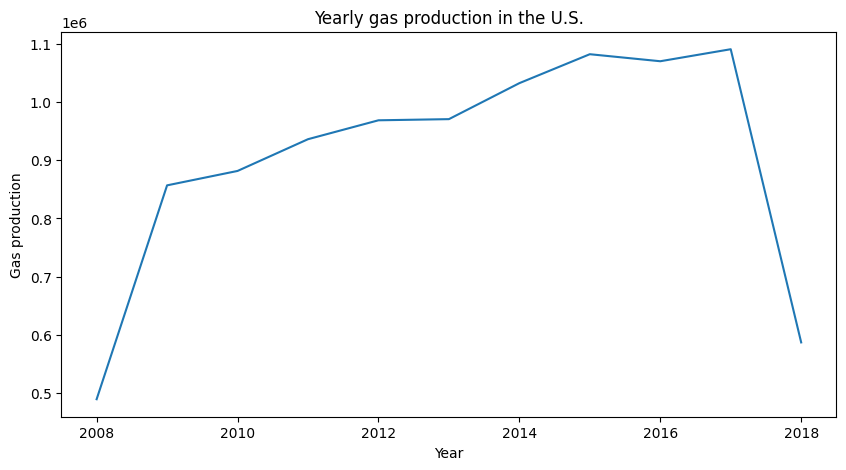

In [17]:
# GOAL: plot the total yearly gas production of the whole US

# filter(items=['U.S.']) keeps only the 'U.S.' column (the national total)
# -> we get a small dataframe: one row per year, one column
us_yearly_gas = yearly_gas_df.filter(items=['U.S.'])

# plot() draws a line chart: years on the x-axis (the index), production on the y-axis
us_yearly_gas.plot(
    title='Yearly gas production in the U.S.',   # chart title
    xlabel='Year',                                # x-axis label
    ylabel='Gas production',                      # y-axis label
    figsize=(10, 5),                              # chart size (width, height)
    legend=False                                  # only one line, no need for a legend
);


2009 2017


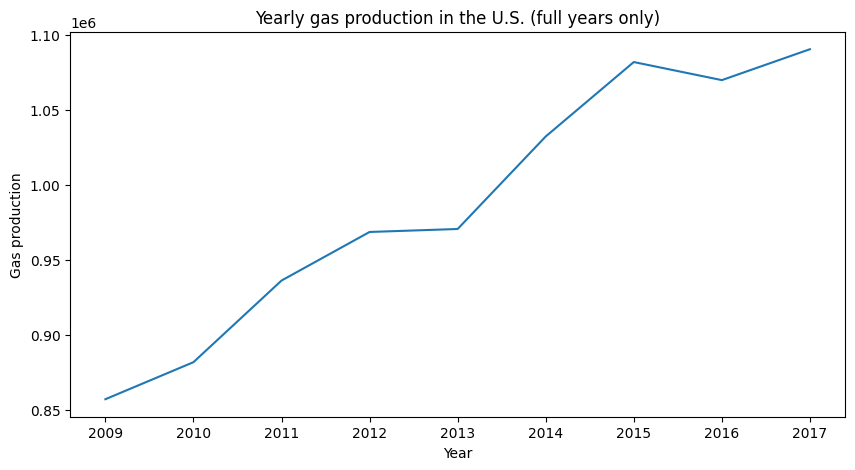

In [18]:
import numpy as np

# GOAL: keep only the full years (2009 to 2017) and plot the US production again

# 1. Build the condition: True for the years between 2009 and 2017, False for the others
#    np.logical_and(A, B) is True only when A AND B are both True
full_years = np.logical_and(yearly_gas_df.index >= 2009, yearly_gas_df.index <= 2017)

# 2. Boolean indexing: df[condition] keeps only the rows where the condition is True
#    -> 2008 and 2018 (incomplete years) are removed
yearly_gas_df = yearly_gas_df[full_years]

# Quick check: the first year should be 2009 and the last one 2017
print(yearly_gas_df.index.min(), yearly_gas_df.index.max())

# 3. Plot the total US production, now on full years only
yearly_gas_df.filter(items=['U.S.']).plot(
    title='Yearly gas production in the U.S. (full years only)',
    xlabel='Year',
    ylabel='Gas production',
    figsize=(10, 5),
    legend=False
);

### State production

Let's have a look at the yearly production of some specific states

In [20]:
full_yearly_gas_df = yearly_gas_df[np.logical_and(yearly_gas_df.index >= 2009,
                                                  yearly_gas_df.index <= 2017)]

In [21]:
# All the columns except the first one ('U.S.', the national total), sorted alphabetically
# -> the list of states we can choose from
full_yearly_gas_df.columns[1:].sort_values()

Index(['Alaska', 'Arkansas', 'California', 'Colorado',
       'Federal Offshore--Gulf of Mexico', 'Kansas', 'Louisiana', 'Montana',
       'New Mexico', 'North Dakota', 'Ohio', 'Oklahoma', 'Other States',
       'Pennsylvania', 'Texas', 'Utah', 'West Virginia', 'Wyoming'],
      dtype='object')

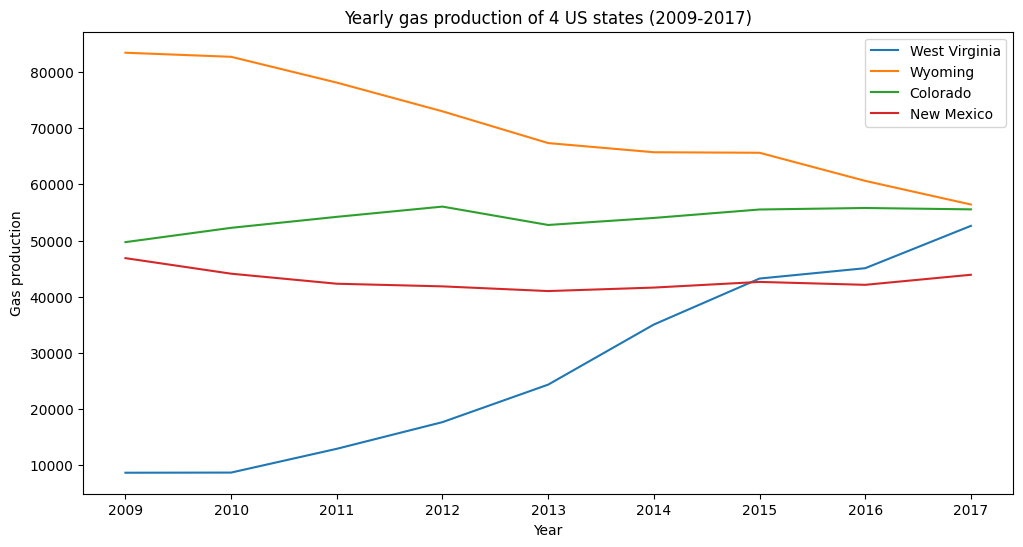

In [22]:
# GOAL: compare the yearly gas production of 4 other states

# 4 states with different stories:
# - West Virginia: shale gas boom (Marcellus formation, like Pennsylvania)
# - Wyoming: big historical producer
# - Colorado: large gas fields in the Rocky Mountains
# - New Mexico: oil and gas from the Permian basin
states = ['West Virginia', 'Wyoming', 'Colorado', 'New Mexico']

# filter(items=...) keeps only these 4 columns, plot() draws one line per state
full_yearly_gas_df.filter(items=states).plot(
    title='Yearly gas production of 4 US states (2009-2017)',
    xlabel='Year',
    ylabel='Gas production',
    figsize=(12, 6)
);

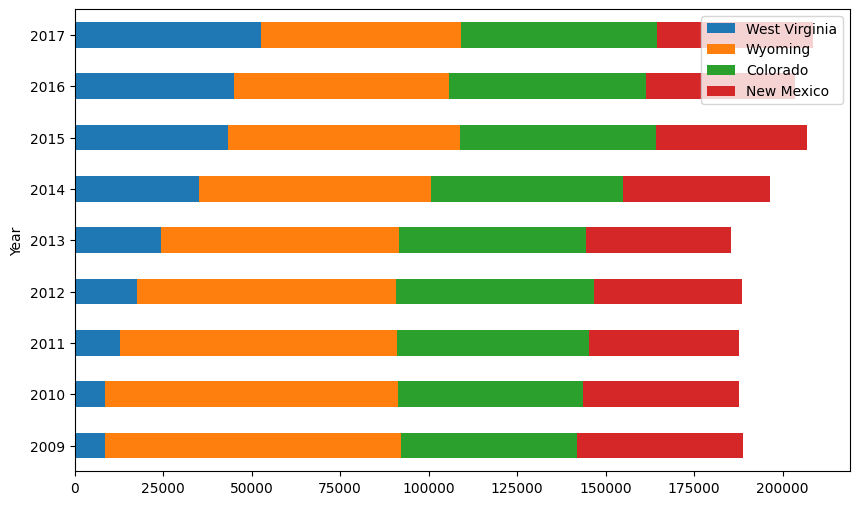

In [23]:
# One horizontal bar per year, split into the production of each state
full_yearly_gas_df.filter(items=states).plot(kind='barh', stacked=True, figsize=(10, 6));

---

## Comparing with Crude Oil Production

In [24]:
file = "U.S._crude_oil_production.csv"
oil_df = pd.read_csv(file)
oil_df.head()

,Month,U.S. Crude Oil,Alabama,Alaska,Arkansas,Arizona,California,Colorado,Federal Offshore Gulf of Mexico Crude Oil,Federal Offshore Pacific Crude Oil,...,Ohio,Oklahoma,Pennsylvania,South Dakota,Wyoming,West Virginia,Virginia,Utah,Texas,Tennessee
0,2008-06-01,5138,21,655,17,0,583,82,1326,67,...,14,186,8,5,144,6,0,60,1097,1
1,2008-07-01,5177,21,640,17,0,586,81,1372,61,...,14,184,8,5,145,5,0,61,1111,1
2,2008-08-01,5003,21,544,17,0,588,82,1272,70,...,14,188,8,5,145,6,0,62,1110,1
3,2008-09-01,3974,21,681,16,0,587,88,242,67,...,14,186,8,5,144,6,0,63,1055,1
4,2008-10-01,4738,21,716,17,0,586,86,803,66,...,14,185,8,5,145,6,0,64,1125,1


In [27]:

oil_df['Month'] = pd.to_datetime(oil_df['Month'])
oil_df.dtypes.head(3)  

Month              datetime64[ns]
U.S. Crude Oil              int64
Alabama                     int64
dtype: object

In [28]:
# Yearly US total, full years only (2009-2017), renamed by commodity
yearly_gas = gas_df.groupby(gas_df['Month'].dt.year).sum(numeric_only=True).filter(items=['U.S.'])
yearly_gas = yearly_gas[np.logical_and(yearly_gas.index >= 2009, yearly_gas.index <= 2017)]
yearly_gas = yearly_gas.rename(columns={'U.S.': 'Gas'})

yearly_oil = oil_df.groupby(oil_df['Month'].dt.year).sum(numeric_only=True).filter(items=['U.S.'])
yearly_oil = yearly_oil[np.logical_and(yearly_oil.index >= 2009, yearly_oil.index <= 2017)]
yearly_oil = yearly_oil.rename(columns={'U.S.': 'Crude oil'})

In [29]:
# Side by side (axis=1), aligned on the year
yearly_merged = pd.concat([yearly_gas, yearly_oil], axis=1)
yearly_merged

,Gas
Month,
2009,856876
2010,881622
2011,936163
2012,968632
2013,970617
2014,1032439
2015,1082158
2016,1070085
2017,1090730


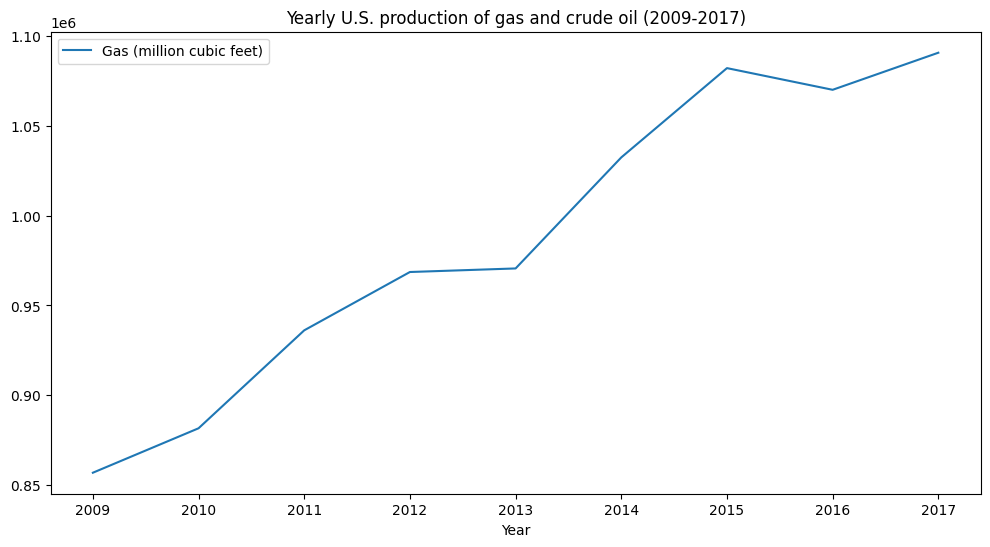

In [30]:
# Plot with the units from Kaggle in the legend
ax = yearly_merged.plot(title='Yearly U.S. production of gas and crude oil (2009-2017)',
                        xlabel='Year', figsize=(12, 6))
ax.legend(['Gas (million cubic feet)', 'Crude oil (thousand barrels)']);